# Estimación de RUL en N-CMAPSS (DS02) — Pipeline v01

## Objetivo de este avance

Establecer un protocolo experimental **metodológicamente válido** para evaluar si el
mecanismo de atención temporal (alternativa A4 seleccionada) aporta una mejora real
sobre la arquitectura híbrida 1D-CNN + LSTM, sobre el subconjunto DS02 del N-CMAPSS.

## Estudio de ablación: tres brazos

La arquitectura es **idéntica** en los tres brazos salvo por el módulo de agregación
temporal que colapsa la secuencia de salida del LSTM en un vector de características:

| Brazo | Agregación | Parámetros extra | Qué aísla |
|---|---|---|---|
| `last` | último estado oculto $h_T$ | 0 | Línea base clásica |
| `mean` | promedio temporal $\frac{1}{T}\sum_t h_t$ | 0 | Efecto de *agregar toda la ventana* |
| `attention` | atención aditiva (Bahdanau) | 4.224 | Efecto de la *ponderación aprendida* |

El brazo `mean` es el control que faltaba: tiene el mismo número de parámetros que
`last` pero agrega sobre toda la ventana igual que `attention`. Sin él no es posible
distinguir si una eventual mejora se debe al mecanismo de atención o simplemente a
usar información de todos los instantes de la ventana.

## Correcciones metodológicas respecto de la versión anterior (`../ProjectV00/RULv00.ipynb`)

1. **Partición por unidad**, no por índice. La versión anterior cortaba en
   `int(0.8*N)` sobre ventanas ordenadas por motor, lo que dejaba la unidad 18
   simultáneamente en entrenamiento y validación, con ventanas solapadas en 25 de
   30 pasos a ambos lados del corte.
2. **Normalización sin fuga**: el `StandardScaler` se ajusta *solo* con las unidades
   de entrenamiento.
3. **Early stopping y selección del mejor checkpoint** en los tres brazos. Antes se
   reportaba la última época, lo que comparaba el peor punto de la línea base contra
   el mejor punto de la propuesta.
4. **Conjunto de prueba oficial**: unidades 11, 14 y 15 (`*_test` del HDF5), nunca
   usadas para entrenar ni para seleccionar. Es lo que permite comparar contra la
   literatura.
5. **Tres semillas por brazo** y reporte como media ± desviación estándar.
6. **Ventanas restringidas al ciclo de vuelo**: no cruzan la frontera entre un
   aterrizaje y el despegue siguiente.
7. **Umbral PwL derivado de los datos** mediante el indicador de estado de salud
   `hs`, en lugar del valor 125 heredado del C-MAPSS clásico (inerte en DS02, donde
   el RUL máximo es 88 ciclos).
8. **Métricas por unidad** y *score* NASA normalizado por número de muestras.

## 0. Dependencias

Si falta alguna, descomentar y ejecutar una sola vez:

```python
%pip install h5py scikit-learn torch pandas numpy matplotlib seaborn
```

In [25]:
import os
import json
import math
import time
import random
import warnings

import h5py
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings("ignore", category=UserWarning)

%matplotlib inline

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | dispositivo activo: {device}")

PyTorch 2.7.1+cpu | dispositivo activo: cpu


## 1. Configuración del experimento

Todos los hiperparámetros y decisiones de diseño viven aquí, en un único lugar
citable desde el informe.

`SMOKE_TEST = True` ejecuta el pipeline completo en pocos minutos (una semilla, dos
épocas, submuestra de ventanas) para verificar que todo corre de principio a fin.
Ponerlo en `False` para la corrida definitiva.

In [26]:
SMOKE_TEST = False          # True = verificación rápida; False = corrida definitiva

DATASET_PATH = "D:/Ramos/Memoria_Titulacion_ELO308/Dataset/N-CMAPSS_DS02-006.h5"
OUT_DIR = "results"
os.makedirs(OUT_DIR, exist_ok=True)

# --- Preprocesamiento ---
SAMPLE_STEP = 10            # submuestreo temporal: 1 muestra cada 10 s (datos a 1 Hz)
WINDOW_SIZE = 30            # 30 pasos x 10 s = 300 s de vuelo por ventana
STRIDE = 10                 # solapamiento de 20/30 pasos entre ventanas consecutivas
USE_PWL = True              # recorte lineal por tramos del RUL (umbral derivado de 'hs')

# --- Partición por unidad (DS02) ---
# dev  = {2, 5, 10, 16, 18, 20}   test oficial = {11, 14, 15}
TRAIN_UNITS = [2.0, 5.0, 10.0, 16.0]   # 2 modos de falla: HPT (2,5,10) y HPT+LPT (16)
VAL_UNITS = [18.0, 20.0]               # ambas HPT+LPT, nunca vistas en entrenamiento

# --- Modelo ---
CONV_CHANNELS = 32
HIDDEN_SIZE = 64
DROPOUT = 0.2

# --- Entrenamiento ---
ARMS = ["last", "mean", "attention"]
SEEDS = [0, 1, 2]
BATCH_SIZE = 256
MAX_EPOCHS = 30
PATIENCE = 5                # épocas sin mejora en RMSE de validación antes de detener
LR = 1e-3
WEIGHT_DECAY = 1e-4

if SMOKE_TEST:
    SEEDS = [0]
    MAX_EPOCHS = 2
    PATIENCE = 2

# --- Paleta de figuras (slots 1-3 de la paleta categórica de referencia) ---
COLORS = {"attention": "#2a78d6", "last": "#eb6834", "mean": "#1baf7a"}
ARM_LABEL = {
    "last": r"Último estado $h_T$",
    "mean": "Promedio temporal",
    "attention": "Atención temporal",
}
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ_LOW, SEQ_HIGH = "#86b6ef", "#1c5cab"   # rampa secuencial azul (magnitud)

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK_2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False,
})

print(f"Modo: {'SMOKE TEST' if SMOKE_TEST else 'CORRIDA DEFINITIVA'}")
print(f"Brazos: {ARMS} | semillas: {SEEDS} | {len(ARMS)*len(SEEDS)} entrenamientos")

Modo: CORRIDA DEFINITIVA
Brazos: ['last', 'mean', 'attention'] | semillas: [0, 1, 2] | 9 entrenamientos


## 2. Carga desde HDF5

Se leen ambas particiones oficiales (`dev` y `test`) aplicando el submuestreo
directamente en el *slicing* de h5py, para no materializar los 5,3 M de registros
en RAM. El resultado se cachea en un `.npz` para que las re-ejecuciones sean
inmediatas.

**Variables utilizadas:** las 4 condiciones de operación `W` (alt, Mach, TRA, T2) y
los 14 sensores físicos `X_s`. Se descartan deliberadamente los sensores virtuales
`X_v` y los parámetros de salud del modelo `T`: no son medibles en un motor real, y
usarlos convertiría el problema en uno artificialmente fácil y no transferible.

In [27]:
def _names(f, key):
    """Decodifica los nombres de variables almacenados en el HDF5."""
    return [v.decode() if isinstance(v, bytes) else str(v)
            for v in np.array(f[key]).flatten()]


def load_ncmapss(file_path, sample_step=10, cache_dir=OUT_DIR):
    """
    Carga las particiones oficiales 'dev' y 'test' del N-CMAPSS.

    Devuelve un dict con, por partición: features (W|X_s), rul, unit, cycle, hs.
    """
    cache = os.path.join(cache_dir, f"cache_step{sample_step}.npz")
    meta_file = os.path.join(cache_dir, f"cache_step{sample_step}_vars.json")

    if os.path.exists(cache) and os.path.exists(meta_file):
        print(f"Cargando desde caché: {cache}")
        z = np.load(cache)
        with open(meta_file, encoding="utf-8") as fh:
            var_names = json.load(fh)
        data = {s: {k: z[f"{s}_{k}"] for k in ("features", "rul", "unit", "cycle", "hs")}
                for s in ("dev", "test")}
        return data, var_names

    if not os.path.exists(file_path):
        raise FileNotFoundError(f"No se encontró {file_path}")

    data = {}
    print(f"Leyendo {file_path} (submuestreo 1/{sample_step})...")
    with h5py.File(file_path, "r") as f:
        var_names = {"W": _names(f, "W_var"),
                     "X_s": _names(f, "X_s_var"),
                     "A": _names(f, "A_var")}
        for split in ("dev", "test"):
            W = np.array(f[f"W_{split}"][::sample_step], dtype=np.float32)
            Xs = np.array(f[f"X_s_{split}"][::sample_step], dtype=np.float32)
            Y = np.array(f[f"Y_{split}"][::sample_step], dtype=np.float32).ravel()
            A = np.array(f[f"A_{split}"][::sample_step], dtype=np.float32)
            data[split] = {"features": np.hstack([W, Xs]).astype(np.float32),
                           "rul": Y,
                           "unit": A[:, 0], "cycle": A[:, 1], "hs": A[:, 3]}
            print(f"  {split:4s}: {data[split]['features'].shape[0]:>7d} registros x "
                  f"{data[split]['features'].shape[1]} señales")

    np.savez_compressed(cache, **{f"{s}_{k}": v
                                  for s, d in data.items() for k, v in d.items()})
    with open(meta_file, "w", encoding="utf-8") as fh:
        json.dump(var_names, fh, ensure_ascii=False, indent=2)
    print(f"Caché guardada en {cache}")
    return data, var_names


data, var_names = load_ncmapss(DATASET_PATH, SAMPLE_STEP)
FEATURE_NAMES = var_names["W"] + var_names["X_s"]
NUM_FEATURES = len(FEATURE_NAMES)
print(f"\nCondiciones W ({len(var_names['W'])}): {var_names['W']}")
print(f"Sensores X_s ({len(var_names['X_s'])}): {var_names['X_s']}")
print(f"Auxiliares A: {var_names['A']}")
print(f"Total de canales de entrada: {NUM_FEATURES}")

Cargando desde caché: results\cache_step10.npz

Condiciones W (4): ['alt', 'Mach', 'TRA', 'T2']
Sensores X_s (14): ['T24', 'T30', 'T48', 'T50', 'P15', 'P2', 'P21', 'P24', 'Ps30', 'P40', 'P50', 'Nf', 'Nc', 'Wf']
Auxiliares A: ['unit', 'cycle', 'Fc', 'hs']
Total de canales de entrada: 18


## 3. Caracterización del dataset

Antes de modelar, se verifican los supuestos del preprocesamiento. Esta sección
existe para dejar por escrito por qué se descartan dos convenciones heredadas del
C-MAPSS clásico (2008) que no aplican a N-CMAPSS.

In [28]:
dev, test = data["dev"], data["test"]

rows = []
for split, d in (("dev", dev), ("test", test)):
    for u in np.unique(d["unit"]):
        m = d["unit"] == u
        # el RUL en el instante en que 'hs' pasa de sano (1) a degradado (0)
        deg = d["rul"][m & (d["hs"] == 0)]
        rows.append({
            "Partición": split,
            "Unidad": int(u),
            "Muestras": int(m.sum()),
            "Ciclos (EOL)": int(d["cycle"][m].max()),
            "RUL máx": float(d["rul"][m].max()),
            "RUL en transición sano→degradado": float(deg.max()) if deg.size else np.nan,
        })

units_df = pd.DataFrame(rows)
print(units_df.to_string(index=False))

rul_max_global = float(dev["rul"].max())
pct_over_125 = 100.0 * np.mean(dev["rul"] > 125)
print(f"\nRUL máximo en 'dev': {rul_max_global:.0f} ciclos "
      f"| muestras con RUL > 125: {pct_over_125:.2f} %")
print("→ El umbral PwL de 125 ciclos del C-MAPSS clásico es INERTE en DS02.")

# Umbral PwL derivado de los datos: mediana del RUL de transición de las unidades
# de entrenamiento. Antes de ese punto el motor está sano y su RUL no es observable
# a partir de los sensores.
train_rows = units_df[(units_df["Partición"] == "dev")
                      & (units_df["Unidad"].isin([int(u) for u in TRAIN_UNITS]))]
RUL_MAX = float(np.round(train_rows["RUL en transición sano→degradado"].median()))
print(f"\nUmbral PwL derivado de 'hs' (mediana en unidades de entrenamiento): "
      f"{RUL_MAX:.0f} ciclos")

# Tramos de evaluación por terciles del RUL de entrenamiento (no los 40/80 del
# C-MAPSS clásico, que dejaban el tramo 'late' sin muestras).
tr_mask_raw = np.isin(dev["unit"], TRAIN_UNITS)
_y_tr = np.clip(dev["rul"][tr_mask_raw], 0.0, RUL_MAX) if USE_PWL else dev["rul"][tr_mask_raw]
BIN_EDGES = [0.0, float(np.round(np.quantile(_y_tr, 1 / 3))),
             float(np.round(np.quantile(_y_tr, 2 / 3))), np.inf]
BIN_LABELS = [f"Crítico (RUL ≤ {BIN_EDGES[1]:.0f})",
              f"Medio ({BIN_EDGES[1]:.0f} < RUL ≤ {BIN_EDGES[2]:.0f})",
              f"Sano (RUL > {BIN_EDGES[2]:.0f})"]
print(f"Tramos de evaluación (terciles de entrenamiento): {BIN_EDGES[:-1]} → ∞")

Partición  Unidad  Muestras  Ciclos (EOL)  RUL máx  RUL en transición sano→degradado
      dev       2     85315            75     74.0                              58.0
      dev       5    103342            89     88.0                              72.0
      dev      10     95271            82     81.0                              65.0
      dev      16     76529            63     62.0                              47.0
      dev      18     89072            71     70.0                              54.0
      dev      20     76816            66     65.0                              49.0
     test      11     66350            59     58.0                              40.0
     test      14     15678            76     75.0                              40.0
     test      15     43347            67     66.0                              43.0

RUL máximo en 'dev': 88 ciclos | muestras con RUL > 125: 0.00 %
→ El umbral PwL de 125 ciclos del C-MAPSS clásico es INERTE en DS02.

Umbral PwL deri

## 4. Partición por unidad

La regla es que **ninguna unidad aparece en más de un conjunto**. Un motor es la
unidad estadística natural del problema: en operación, el modelo se enfrenta a
motores que nunca ha visto, no a tramos nuevos de motores conocidos.

- **Entrenamiento:** unidades 2, 5, 10 (falla HPT) y 16 (falla HPT+LPT)
- **Validación:** unidades 18 y 20 (HPT+LPT) — selección de época y de modelo
- **Prueba:** unidades 11, 14 y 15 (partición `test` oficial) — se toca una sola vez

In [29]:
train_mask = np.isin(dev["unit"], TRAIN_UNITS)
val_mask = np.isin(dev["unit"], VAL_UNITS)
assert not np.any(train_mask & val_mask), "Una unidad no puede estar en ambos conjuntos"
assert len(np.intersect1d(np.unique(dev["unit"]), np.unique(test["unit"]))) == 0

print(f"Entrenamiento : unidades {sorted(int(u) for u in TRAIN_UNITS)} "
      f"— {train_mask.sum():>7d} registros")
print(f"Validación    : unidades {sorted(int(u) for u in VAL_UNITS)} "
      f"— {val_mask.sum():>7d} registros")
print(f"Prueba (hold-out): unidades {sorted(int(u) for u in np.unique(test['unit']))} "
      f"— {len(test['unit']):>7d} registros")

Entrenamiento : unidades [2, 5, 10, 16] —  360457 registros
Validación    : unidades [18, 20] —  165888 registros
Prueba (hold-out): unidades [11, 14, 15] —  125375 registros


## 5. Normalización sin fuga de información

El `StandardScaler` se ajusta **exclusivamente** con los registros de las unidades de
entrenamiento. Validación y prueba solo se transforman. Ajustarlo sobre el conjunto
completo, como en la versión anterior, filtra la media y la varianza de los datos de
evaluación hacia el entrenamiento.

In [30]:
scaler = StandardScaler().fit(dev["features"][train_mask])

dev_scaled = scaler.transform(dev["features"]).astype(np.float32)
test_scaled = scaler.transform(test["features"]).astype(np.float32)

print(f"Scaler ajustado con {train_mask.sum():,} registros de entrenamiento.")
print(f"Media (entrenamiento, primeras 4): {scaler.mean_[:4].round(2)}")
print(f"Media de las unidades de validación tras transformar (debe alejarse de 0): "
      f"{dev_scaled[val_mask][:, :4].mean(axis=0).round(3)}")

# Etiquetas con recorte lineal por tramos (PwL)
rul_dev = np.clip(dev["rul"], 0.0, RUL_MAX) if USE_PWL else dev["rul"].copy()
rul_test = np.clip(test["rul"], 0.0, RUL_MAX) if USE_PWL else test["rul"].copy()

Scaler ajustado con 360,457 registros de entrenamiento.
Media (entrenamiento, primeras 4): [2.181361e+04 6.200000e-01 6.842000e+01 4.751700e+02]
Media de las unidades de validación tras transformar (debe alejarse de 0): [ 0.044  0.061  0.028 -0.032]


## 6. Ventaneo temporal restringido al ciclo de vuelo

Las ventanas deslizantes se construyen dentro de segmentos contiguos de
`(unidad, ciclo)`. Una ventana que cruzara la frontera entre dos vuelos mezclaría el
descenso final de un vuelo con el despegue del siguiente: un salto abrupto en
altitud, Mach y empuje que no corresponde a ninguna dinámica física continua. En la
versión anterior, que solo enmascaraba por unidad, el 2,43 % de las ventanas cruzaba
esa frontera.

La etiqueta de cada ventana es el RUL del **último** instante, que es la convención
estándar en la literatura de pronóstico.

In [31]:
def create_windows(features, ruls, units, cycles, window_size, stride):
    """
    Ventanas deslizantes que nunca cruzan una frontera de (unidad, ciclo).

    Devuelve X (N, window_size, F), y (N,) y meta (N, 2) con [unidad, ciclo].
    """
    key = np.stack([units, cycles], axis=1)
    change = np.any(np.diff(key, axis=0) != 0, axis=1)
    bounds = np.concatenate([[0], np.where(change)[0] + 1, [len(units)]])

    starts = []
    for s, e in zip(bounds[:-1], bounds[1:]):
        n = e - s
        if n < window_size:
            continue
        starts.append(s + np.arange((n - window_size) // stride + 1) * stride)
    starts = np.concatenate(starts)

    idx = starts[:, None] + np.arange(window_size)[None, :]
    last = starts + window_size - 1
    X = features[idx]
    y = ruls[last]
    meta = np.stack([units[last], cycles[last]], axis=1)
    return X.astype(np.float32), y.astype(np.float32), meta


t0 = time.time()
X_dev, y_dev, meta_dev = create_windows(
    dev_scaled, rul_dev, dev["unit"], dev["cycle"], WINDOW_SIZE, STRIDE)
X_test, y_test, meta_test = create_windows(
    test_scaled, rul_test, test["unit"], test["cycle"], WINDOW_SIZE, STRIDE)

win_train = np.isin(meta_dev[:, 0], TRAIN_UNITS)
win_val = np.isin(meta_dev[:, 0], VAL_UNITS)

X_train, y_train, meta_train = X_dev[win_train], y_dev[win_train], meta_dev[win_train]
X_val, y_val, meta_val = X_dev[win_val], y_dev[win_val], meta_dev[win_val]

if SMOKE_TEST:
    rng = np.random.default_rng(0)
    sel_tr = rng.choice(len(X_train), size=min(4000, len(X_train)), replace=False)
    sel_va = rng.choice(len(X_val), size=min(2000, len(X_val)), replace=False)
    X_train, y_train, meta_train = X_train[sel_tr], y_train[sel_tr], meta_train[sel_tr]
    X_val, y_val, meta_val = X_val[sel_va], y_val[sel_va], meta_val[sel_va]

print(f"Ventaneo completado en {time.time() - t0:.1f} s\n")
for name, Xa, ya in (("Entrenamiento", X_train, y_train),
                     ("Validación", X_val, y_val),
                     ("Prueba", X_test, y_test)):
    print(f"{name:14s}: X = {str(Xa.shape):>20s} | y = {str(ya.shape):>10s} | "
          f"RUL medio = {ya.mean():5.1f} | {Xa.nbytes / 1e6:6.1f} MB")

# Verificación explícita de ausencia de fuga entre conjuntos
assert len(np.intersect1d(np.unique(meta_train[:, 0]), np.unique(meta_val[:, 0]))) == 0
assert len(np.intersect1d(np.unique(meta_train[:, 0]), np.unique(meta_test[:, 0]))) == 0
print("\n✓ Sin unidades compartidas entre entrenamiento, validación y prueba.")

Ventaneo completado en 0.1 s

Entrenamiento : X =      (35287, 30, 18) | y =   (35287,) | RUL medio =  37.1 |   76.2 MB
Validación    : X =      (16251, 30, 18) | y =   (16251,) | RUL medio =  33.3 |   35.1 MB
Prueba        : X =      (12047, 30, 18) | y =   (12047,) | RUL medio =  31.0 |   26.0 MB

✓ Sin unidades compartidas entre entrenamiento, validación y prueba.


## 7. Dataset y DataLoaders

`num_workers=0` es obligatorio para ejecutar en un notebook sobre Windows: el modelo
de multiprocesamiento por *spawn* no puede serializar el contexto del kernel.

In [32]:
class NCMAPSSDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(np.ascontiguousarray(X))
        self.y = torch.from_numpy(np.ascontiguousarray(y)).unsqueeze(1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


ds_train = NCMAPSSDataset(X_train, y_train)
ds_val = NCMAPSSDataset(X_val, y_val)
ds_test = NCMAPSSDataset(X_test, y_test)

val_loader = DataLoader(ds_val, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(ds_test, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Lotes por época — entrenamiento: {math.ceil(len(ds_train) / BATCH_SIZE)} "
      f"| validación: {len(val_loader)} | prueba: {len(test_loader)}")

Lotes por época — entrenamiento: 138 | validación: 64 | prueba: 48


## 8. Arquitectura híbrida con agregación temporal intercambiable

```
Entrada (B, 30, 18)
  → Conv1D(18→32, k=3, padding=1) + BatchNorm + ReLU + Dropout(0.2)
  → LSTM(32→64), secuencia completa (B, 30, 64)
  → AGREGACIÓN ∈ {last, mean, attention}  →  (B, 64)
  → Linear(64→32) + ReLU → Linear(32→1)
```

El parámetro `aggregation` es la **única** diferencia entre los tres brazos, que es
la condición para que la ablación sea interpretable.

La atención aditiva de Bahdanau calcula
$e_t = v^\top \tanh(W h_t)$, $\alpha_t = \mathrm{softmax}(e_t)$,
$c = \sum_t \alpha_t h_t$.

In [33]:
class TemporalAttention(nn.Module):
    """Atención aditiva (Bahdanau) sobre la dimensión temporal."""

    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Linear(hidden_dim, hidden_dim)
        self.v = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, h):                      # h: (B, T, H)
        energy = torch.tanh(self.attn(h))
        scores = self.v(energy)                # (B, T, 1)
        weights = torch.softmax(scores, dim=1)
        context = torch.sum(weights * h, dim=1)  # (B, H)
        return context, weights.squeeze(-1)


class RULPredictor(nn.Module):
    def __init__(self, num_features, aggregation="attention",
                 conv_channels=CONV_CHANNELS, hidden=HIDDEN_SIZE, dropout=DROPOUT):
        super().__init__()
        assert aggregation in ("last", "mean", "attention")
        self.aggregation = aggregation

        self.conv = nn.Conv1d(num_features, conv_channels, kernel_size=3, padding=1)
        self.bn = nn.BatchNorm1d(conv_channels)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(conv_channels, hidden, batch_first=True)
        self.attention = TemporalAttention(hidden) if aggregation == "attention" else None
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):                       # x: (B, T, F)
        z = x.permute(0, 2, 1)                  # (B, F, T)
        z = self.dropout(self.relu(self.bn(self.conv(z))))
        z = z.permute(0, 2, 1)                  # (B, T, C)
        h, _ = self.lstm(z)                     # (B, T, H)

        weights = None
        if self.aggregation == "attention":
            feat, weights = self.attention(h)
        elif self.aggregation == "mean":
            feat = h.mean(dim=1)
        else:
            feat = h[:, -1, :]
        return self.head(feat), weights


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print(f"{'Brazo':<12}{'Parámetros':>12}{'Δ vs. baseline':>16}")
_base = count_params(RULPredictor(NUM_FEATURES, "last"))
for arm in ARMS:
    n = count_params(RULPredictor(NUM_FEATURES, arm))
    print(f"{arm:<12}{n:>12,}{n - _base:>+16,}")

Brazo         Parámetros  Δ vs. baseline
last              29,025              +0
mean              29,025              +0
attention         33,249          +4,224


## 9. Entrenamiento con early stopping

Se conserva el `state_dict` de la época con **menor RMSE de validación** y se
restaura al terminar. Sin esto, la comparación entre brazos depende de en qué punto
de su curva quedó cada modelo al agotarse el presupuesto de épocas: en la versión
anterior la línea base se reportaba en su peor época (RMSE 9,02) frente a la
propuesta en su mejor época (RMSE 6,67), inflando artificialmente la mejora
reportada de un ~9 % real a un 26 %.

In [34]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


@torch.no_grad()
def predict(model, loader, collect_weights=False):
    model.eval()
    preds, weights = [], []
    for X_b, _ in loader:
        out, w = model(X_b.to(device))
        preds.append(out.cpu().numpy().ravel())
        if collect_weights and w is not None:
            weights.append(w.cpu().numpy())
    preds = np.concatenate(preds)
    weights = np.concatenate(weights) if weights else None
    return preds, weights


def train_arm(aggregation, seed, verbose=True):
    set_seed(seed)
    g = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=0, generator=g, drop_last=True)

    model = RULPredictor(NUM_FEATURES, aggregation).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    history = {"train_rmse": [], "val_rmse": []}
    best = {"rmse": np.inf, "epoch": -1, "state": None}
    stale, epoch_times = 0, []

    for epoch in range(1, MAX_EPOCHS + 1):
        t_start = time.time()
        model.train()
        running, n = 0.0, 0
        for X_b, y_b in train_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            out, _ = model(X_b)
            loss = criterion(out, y_b)
            loss.backward()
            optimizer.step()
            running += loss.item() * X_b.size(0)
            n += X_b.size(0)
        train_rmse = math.sqrt(running / n)

        val_pred, _ = predict(model, val_loader)
        val_rmse = float(np.sqrt(np.mean((val_pred - y_val) ** 2)))

        history["train_rmse"].append(train_rmse)
        history["val_rmse"].append(val_rmse)
        epoch_times.append(time.time() - t_start)

        if val_rmse < best["rmse"] - 1e-4:
            best = {"rmse": val_rmse, "epoch": epoch,
                    "state": {k: v.detach().cpu().clone()
                              for k, v in model.state_dict().items()}}
            stale = 0
            flag = " *"
        else:
            stale += 1
            flag = ""

        if verbose:
            print(f"  época {epoch:02d}/{MAX_EPOCHS} | train RMSE {train_rmse:6.3f} "
                  f"| val RMSE {val_rmse:6.3f} | {epoch_times[-1]:5.1f} s{flag}")

        if stale >= PATIENCE:
            if verbose:
                print(f"  early stopping (sin mejora en {PATIENCE} épocas)")
            break

    model.load_state_dict(best["state"])
    return model, history, best, float(np.mean(epoch_times))

## 10. Métricas

- **RMSE** y **MAE**, en ciclos.
- **Score NASA asimétrico**, `s = exp(-d/13)-1` si `d<0` y `exp(d/10)-1` si `d≥0`,
  con `d = ŷ - y`. Penaliza más la **sobreestimación** (predecir más vida útil de la
  que queda), que es el falso negativo peligroso en mantenimiento. Se reporta
  **normalizado por número de muestras**: sin normalizar depende del tamaño del
  conjunto y no es comparable entre trabajos.
- **RMSE por tramo** según los terciles de la sección 3.
- **RMSE por unidad**, porque el promedio global sobrerrepresenta a los motores con
  trayectorias más largas.

In [35]:
def nasa_score(y_true, y_pred, normalize=True):
    d = np.asarray(y_pred).ravel() - np.asarray(y_true).ravel()
    s = np.where(d < 0, np.exp(-d / 13.0) - 1.0, np.exp(d / 10.0) - 1.0)
    return float(s.mean() if normalize else s.sum())


def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_pred).ravel()
                                  - np.asarray(y_true).ravel()) ** 2)))


def compute_metrics(y_true, y_pred, meta=None):
    y_true, y_pred = np.asarray(y_true).ravel(), np.asarray(y_pred).ravel()
    out = {
        "RMSE": rmse(y_true, y_pred),
        "MAE": float(np.mean(np.abs(y_pred - y_true))),
        "Score NASA": nasa_score(y_true, y_pred),
        "Sesgo": float(np.mean(y_pred - y_true)),
        "% sobreestimación": float(100.0 * np.mean(y_pred > y_true)),
    }
    for lo, hi, label in zip(BIN_EDGES[:-1], BIN_EDGES[1:], BIN_LABELS):
        m = (y_true > lo) & (y_true <= hi) if lo > 0 else (y_true <= hi)
        out[f"RMSE {label}"] = rmse(y_true[m], y_pred[m]) if m.sum() else np.nan
    if meta is not None:
        for u in np.unique(meta[:, 0]):
            m = meta[:, 0] == u
            out[f"RMSE u{int(u)}"] = rmse(y_true[m], y_pred[m])
    return out

## 11. Ejecución del estudio de ablación

3 brazos × 3 semillas = 9 entrenamientos independientes. Cada uno guarda su mejor
checkpoint en `results/`.

In [36]:
results, histories, models = [], {}, {}
t_global = time.time()

for arm in ARMS:
    for seed in SEEDS:
        print(f"\n{'─' * 70}\n▶ {ARM_LABEL[arm]}  ({arm}) — semilla {seed}\n{'─' * 70}")
        model, history, best, t_epoch = train_arm(arm, seed)

        val_pred, _ = predict(model, val_loader)
        row = {"Brazo": arm, "Semilla": seed, "Mejor época": best["epoch"],
               "Épocas": len(history["val_rmse"]),
               "Parámetros": count_params(model), "s/época": round(t_epoch, 1)}
        row.update(compute_metrics(y_val, val_pred, meta_val))
        results.append(row)

        histories[(arm, seed)] = history
        models[(arm, seed)] = model
        torch.save(best["state"], os.path.join(OUT_DIR, f"ckpt_{arm}_s{seed}.pt"))
        print(f"  → mejor época {best['epoch']} | val RMSE {best['rmse']:.3f} ciclos")

val_df = pd.DataFrame(results)
val_df.to_csv(os.path.join(OUT_DIR, "metrics_val.csv"), index=False)
print(f"\n{'═' * 70}\nTiempo total: {(time.time() - t_global) / 60:.1f} min")


──────────────────────────────────────────────────────────────────────
▶ Último estado $h_T$  (last) — semilla 0
──────────────────────────────────────────────────────────────────────
  época 01/30 | train RMSE 33.566 | val RMSE 19.740 |   4.0 s *
  época 02/30 | train RMSE 20.331 | val RMSE 18.879 |   4.1 s *
  época 03/30 | train RMSE 11.370 | val RMSE  9.747 |   4.3 s *
  época 04/30 | train RMSE  6.757 | val RMSE  6.330 |   3.8 s *
  época 05/30 | train RMSE  6.117 | val RMSE  5.437 |   3.8 s *
  época 06/30 | train RMSE  5.804 | val RMSE  5.217 |   3.8 s *
  época 07/30 | train RMSE  5.871 | val RMSE  6.762 |   4.1 s
  época 08/30 | train RMSE  5.719 | val RMSE  5.749 |   4.0 s
  época 09/30 | train RMSE  5.746 | val RMSE  4.973 |   4.2 s *
  época 10/30 | train RMSE  5.429 | val RMSE  6.492 |   4.1 s
  época 11/30 | train RMSE  5.104 | val RMSE  5.397 |   4.0 s
  época 12/30 | train RMSE  5.563 | val RMSE  6.787 |   3.9 s
  época 13/30 | train RMSE  5.377 | val RMSE  6.019 |   4

## 12. Resultados en validación (unidades 18 y 20)

Estas son las métricas usadas para **seleccionar**. La conclusión sobre si la
atención aporta se sostiene solo si la diferencia entre brazos supera la dispersión
entre semillas.

In [37]:
agg_cols = ["RMSE", "MAE", "Score NASA", "Sesgo", "% sobreestimación"] + \
           [f"RMSE {l}" for l in BIN_LABELS]

summary = (val_df.groupby("Brazo")[agg_cols]
           .agg(["mean", "std"]).reindex(ARMS).round(3))

print("=" * 78)
print(" VALIDACIÓN — media ± desviación estándar sobre", len(SEEDS), "semillas")
print("=" * 78)
for col in agg_cols:
    print(f"\n{col}")
    for arm in ARMS:
        m, s = summary.loc[arm, (col, "mean")], summary.loc[arm, (col, "std")]
        print(f"   {ARM_LABEL[arm]:<26s} {m:8.3f} ± {0.0 if np.isnan(s) else s:.3f}")

base_rmse = summary.loc["last", ("RMSE", "mean")]
att_rmse = summary.loc["attention", ("RMSE", "mean")]
mean_rmse = summary.loc["mean", ("RMSE", "mean")]
att_std = summary.loc["attention", ("RMSE", "std")]
print("\n" + "=" * 78)
print(f"Atención vs. último estado : {100 * (base_rmse - att_rmse) / base_rmse:+.2f} % de RMSE")
print(f"Atención vs. promedio      : {100 * (mean_rmse - att_rmse) / mean_rmse:+.2f} % de RMSE")
print(f"Dispersión entre semillas (atención, ±1σ): {0.0 if np.isnan(att_std) else att_std:.3f} ciclos")
print("=" * 78)
display(val_df[["Brazo", "Semilla", "Mejor época", "Épocas", "Parámetros",
                "s/época", "RMSE", "MAE", "Score NASA"]].round(3))

 VALIDACIÓN — media ± desviación estándar sobre 3 semillas

RMSE
   Último estado $h_T$           4.909 ± 0.285
   Promedio temporal             4.885 ± 0.371
   Atención temporal             4.824 ± 0.248

MAE
   Último estado $h_T$           3.650 ± 0.208
   Promedio temporal             3.506 ± 0.224
   Atención temporal             3.504 ± 0.099

Score NASA
   Último estado $h_T$           0.501 ± 0.044
   Promedio temporal             0.499 ± 0.061
   Atención temporal             0.480 ± 0.045

Sesgo
   Último estado $h_T$           1.772 ± 0.188
   Promedio temporal             1.939 ± 0.589
   Atención temporal             1.479 ± 0.808

% sobreestimación
   Último estado $h_T$          64.663 ± 1.094
   Promedio temporal            63.130 ± 3.685
   Atención temporal            60.220 ± 7.244

RMSE Crítico (RUL ≤ 26)
   Último estado $h_T$           2.716 ± 0.174
   Promedio temporal             2.663 ± 0.428
   Atención temporal             2.543 ± 0.415

RMSE Medio (26 < RUL

,Brazo,Semilla,Mejor época,Épocas,Parámetros,s/época,RMSE,MAE,Score NASA
0,last,0,18,23,29025,4.0,4.615,3.433,0.453
1,last,1,6,11,29025,4.1,4.927,3.666,0.509
2,last,2,9,14,29025,4.1,5.184,3.849,0.541
3,mean,0,9,14,29025,4.2,4.475,3.249,0.430
4,mean,1,10,15,29025,4.1,5.198,3.662,0.547
5,mean,2,6,11,29025,4.1,4.981,3.607,0.518
6,attention,0,15,20,33249,4.7,4.551,3.390,0.429
7,attention,1,10,15,33249,4.8,4.887,3.555,0.495
8,attention,2,9,14,33249,4.7,5.035,3.567,0.515


## 13. Evaluación final sobre el conjunto de prueba oficial

Unidades 11, 14 y 15. **Se evalúa una sola vez**, con los checkpoints ya
seleccionados en validación. Ningún hiperparámetro se ajustó mirando estos datos.

Las unidades 14 y 15 operan vuelos más cortos y a menor altitud que cualquier unidad
de entrenamiento, por lo que este conjunto mide además la capacidad de generalizar a
perfiles operacionales distintos.

In [38]:
test_rows, test_preds, test_weights = [], {}, {}

for arm in ARMS:
    for seed in SEEDS:
        pred, w = predict(models[(arm, seed)], test_loader, collect_weights=True)
        row = {"Brazo": arm, "Semilla": seed}
        row.update(compute_metrics(y_test, pred, meta_test))
        test_rows.append(row)
        test_preds[(arm, seed)] = pred
        if w is not None:
            test_weights[(arm, seed)] = w

test_df = pd.DataFrame(test_rows)
test_df.to_csv(os.path.join(OUT_DIR, "metrics_test.csv"), index=False)

unit_cols = [c for c in test_df.columns if c.startswith("RMSE u")]
test_summary = test_df.groupby("Brazo")[agg_cols + unit_cols].agg(["mean", "std"]).reindex(ARMS)

print("=" * 78)
print(" PRUEBA (hold-out oficial: unidades 11, 14, 15) — media ± σ")
print("=" * 78)
final = pd.DataFrame({
    ARM_LABEL[a]: [f"{test_summary.loc[a, (c, 'mean')]:.3f} ± "
                   f"{0.0 if np.isnan(test_summary.loc[a, (c, 'std')]) else test_summary.loc[a, (c, 'std')]:.3f}"
                   for c in agg_cols + unit_cols]
    for a in ARMS
}, index=agg_cols + unit_cols)
print(final.to_string())
print("=" * 78)

b, a = test_summary.loc["last", ("RMSE", "mean")], test_summary.loc["attention", ("RMSE", "mean")]
m = test_summary.loc["mean", ("RMSE", "mean")]
print(f"\nMejora en prueba, atención vs. último estado : {100 * (b - a) / b:+.2f} %")
print(f"Mejora en prueba, atención vs. promedio      : {100 * (m - a) / m:+.2f} %")

 PRUEBA (hold-out oficial: unidades 11, 14, 15) — media ± σ
                           Último estado $h_T$ Promedio temporal Atención temporal
RMSE                             5.948 ± 0.246     6.006 ± 0.550     5.781 ± 0.381
MAE                              4.698 ± 0.190     4.698 ± 0.503     4.485 ± 0.361
Score NASA                       0.685 ± 0.058     0.714 ± 0.113     0.649 ± 0.080
Sesgo                            2.953 ± 0.743     3.559 ± 0.821     2.670 ± 0.650
% sobreestimación               79.278 ± 3.594    83.343 ± 3.697    77.579 ± 3.778
RMSE Crítico (RUL ≤ 26)          3.584 ± 0.396     3.595 ± 0.535     3.369 ± 0.389
RMSE Medio (26 < RUL ≤ 52)       7.713 ± 0.801     8.218 ± 0.931     7.480 ± 0.706
RMSE Sano (RUL > 52)             5.940 ± 1.349     4.666 ± 0.567     6.114 ± 0.430
RMSE u11                         6.798 ± 0.507     7.072 ± 0.657     6.541 ± 0.710
RMSE u14                         6.136 ± 0.736     5.227 ± 0.425     5.730 ± 0.181
RMSE u15                   

## 14. Figuras

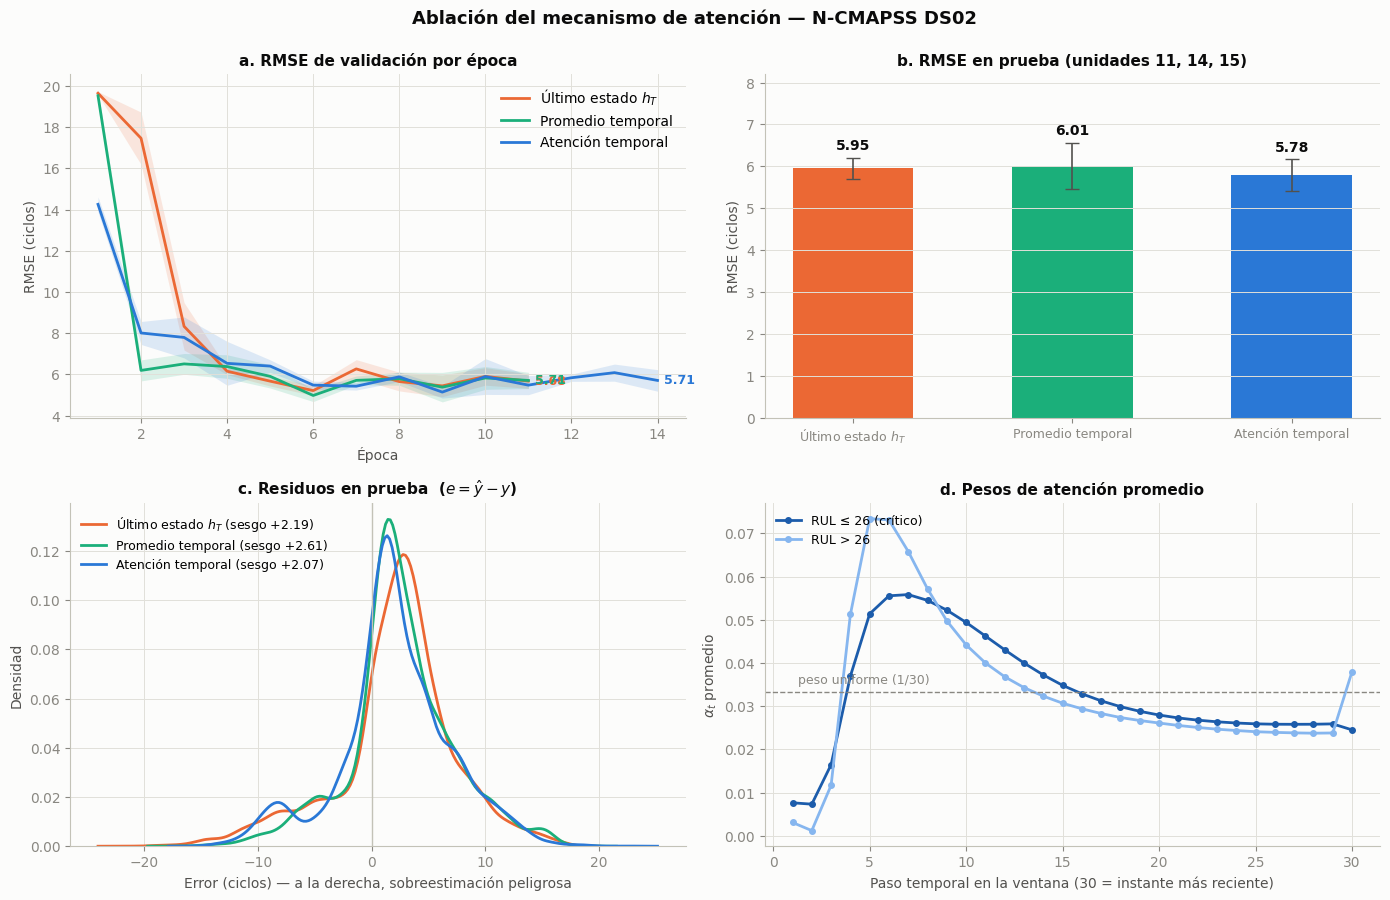

In [39]:
def _band(ax, hist_list, color, label):
    """Curva media con banda ±1σ entre semillas, recortada a la corrida más corta."""
    L = min(len(h) for h in hist_list)
    arr = np.array([h[:L] for h in hist_list])
    ep = np.arange(1, L + 1)
    mu, sd = arr.mean(axis=0), arr.std(axis=0)
    ax.fill_between(ep, mu - sd, mu + sd, color=color, alpha=0.15, linewidth=0)
    ax.plot(ep, mu, color=color, lw=2, label=label)
    ax.annotate(f"{mu[-1]:.2f}", (ep[-1], mu[-1]), xytext=(5, 0),
                textcoords="offset points", color=color, fontsize=9,
                va="center", fontweight="bold")


fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# (a) Curvas de validación
ax = axes[0, 0]
for arm in ARMS:
    _band(ax, [histories[(arm, s)]["val_rmse"] for s in SEEDS], COLORS[arm], ARM_LABEL[arm])
ax.set_title("a. RMSE de validación por época")
ax.set_xlabel("Época")
ax.set_ylabel("RMSE (ciclos)")
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.legend(loc="upper right")

# (b) RMSE en prueba
ax = axes[0, 1]
means = [test_summary.loc[a, ("RMSE", "mean")] for a in ARMS]
stds = [0.0 if np.isnan(test_summary.loc[a, ("RMSE", "std")])
        else test_summary.loc[a, ("RMSE", "std")] for a in ARMS]
xs = np.arange(len(ARMS))
ax.bar(xs, means, width=0.55, color=[COLORS[a] for a in ARMS],
       yerr=stds, capsize=5, ecolor=INK_2, error_kw={"lw": 1.2})
for x, mv, sv in zip(xs, means, stds):
    ax.annotate(f"{mv:.2f}", (x, mv + sv), xytext=(0, 6), textcoords="offset points",
                ha="center", color=INK, fontsize=10, fontweight="bold")
ax.set_xticks(xs)
ax.set_xticklabels([ARM_LABEL[a] for a in ARMS], fontsize=9)
ax.set_title("b. RMSE en prueba (unidades 11, 14, 15)")
ax.set_ylabel("RMSE (ciclos)")
ax.set_ylim(0, max(np.array(means) + np.array(stds)) * 1.25)
ax.grid(axis="x", visible=False)

# (c) Distribución de residuos en prueba (semilla 0)
ax = axes[1, 0]
for arm in ARMS:
    res = test_preds[(arm, SEEDS[0])] - y_test
    sns.kdeplot(res, ax=ax, color=COLORS[arm], lw=2,
                label=f"{ARM_LABEL[arm]} (sesgo {res.mean():+.2f})")
ax.axvline(0, color=AXIS, lw=1)
ax.set_title("c. Residuos en prueba  ($e = \\hat{y} - y$)")
ax.set_xlabel("Error (ciclos) — a la derecha, sobreestimación peligrosa")
ax.set_ylabel("Densidad")
ax.legend(loc="upper left", fontsize=9)

# (d) Pesos de atención por régimen de degradación
ax = axes[1, 1]
if test_weights:
    W_att = np.mean([test_weights[("attention", s)] for s in SEEDS], axis=0)
    crit = y_test <= BIN_EDGES[1]
    steps = np.arange(1, WINDOW_SIZE + 1)
    for m_, color, lab in ((crit, SEQ_HIGH, f"RUL ≤ {BIN_EDGES[1]:.0f} (crítico)"),
                           (~crit, SEQ_LOW, f"RUL > {BIN_EDGES[1]:.0f}")):
        ax.plot(steps, W_att[m_].mean(axis=0), color=color, lw=2, marker="o",
                ms=4, label=lab)
    ax.axhline(1 / WINDOW_SIZE, color=MUTED, lw=1, ls="--")
    ax.annotate("peso uniforme (1/30)", (1, 1 / WINDOW_SIZE), xytext=(4, 6),
                textcoords="offset points", color=MUTED, fontsize=9)
    ax.set_title("d. Pesos de atención promedio")
    ax.set_xlabel("Paso temporal en la ventana (30 = instante más reciente)")
    ax.set_ylabel(r"$\alpha_t$ promedio")
    ax.legend(loc="upper left", fontsize=9)
else:
    ax.axis("off")

fig.suptitle("Ablación del mecanismo de atención — N-CMAPSS DS02",
             fontsize=13, fontweight="bold", color=INK, y=0.995)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "fig_ablacion.png"), dpi=160, bbox_inches="tight")
plt.show()

### Trayectorias de RUL por unidad de prueba

La métrica agregada oculta el comportamiento que importa operacionalmente: cómo
converge la estimación a medida que el motor se acerca al fin de su vida útil. Se
promedian las predicciones de todas las ventanas de cada ciclo de vuelo.

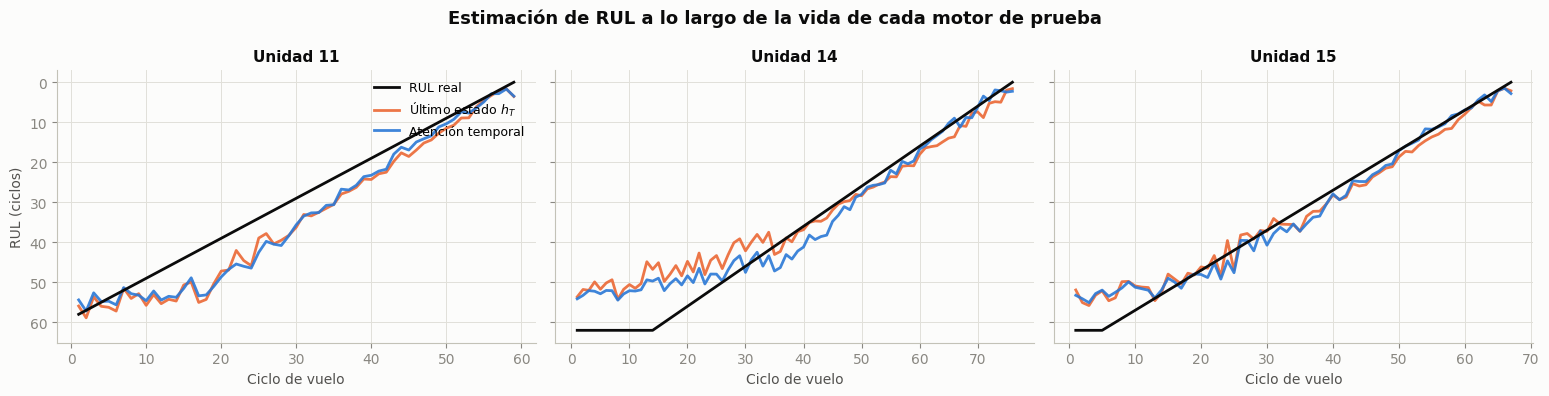


Artefactos guardados en 'results/': métricas (CSV), checkpoints (.pt) y figuras (PNG).


In [40]:
test_units = sorted(np.unique(meta_test[:, 0]))
fig, axes = plt.subplots(1, len(test_units), figsize=(5.2 * len(test_units), 4),
                         sharey=True)
axes = np.atleast_1d(axes)

for ax, u in zip(axes, test_units):
    m = meta_test[:, 0] == u
    cyc = meta_test[m, 1]
    order = np.argsort(cyc)
    cyc_u = cyc[order]
    uniq = np.unique(cyc_u)

    true_c = np.array([y_test[m][order][cyc_u == c].mean() for c in uniq])
    ax.plot(uniq, true_c, color=INK, lw=2, label="RUL real", zorder=3)

    for arm in ("last", "attention"):
        p = test_preds[(arm, SEEDS[0])][m][order]
        pred_c = np.array([p[cyc_u == c].mean() for c in uniq])
        ax.plot(uniq, pred_c, color=COLORS[arm], lw=2, alpha=0.9,
                label=ARM_LABEL[arm], zorder=2)

    ax.set_title(f"Unidad {int(u)}")
    ax.set_xlabel("Ciclo de vuelo")
    ax.invert_yaxis()

axes[0].set_ylabel("RUL (ciclos)")
axes[0].legend(loc="upper right", fontsize=9)
fig.suptitle("Estimación de RUL a lo largo de la vida de cada motor de prueba",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "fig_trayectorias.png"), dpi=160, bbox_inches="tight")
plt.show()

print(f"\nArtefactos guardados en '{OUT_DIR}/': métricas (CSV), checkpoints (.pt) "
      f"y figuras (PNG).")

## 15. Lectura de resultados y próximos pasos

### Cómo interpretar la tabla de la sección 13

La afirmación *"la atención mejora la estimación de RUL"* solo se sostiene si se
cumplen **las dos** condiciones siguientes:

1. `attention` supera a `last` **y** a `mean` por un margen mayor que la dispersión
   entre semillas. Si `mean` ya alcanza a `attention`, la ganancia proviene de
   agregar sobre toda la ventana, no del mecanismo de atención, y el criterio C8
   (interpretabilidad) pasa a ser la única justificación de A4.
2. La ventaja se mantiene en el conjunto de prueba, no solo en validación.

La figura (d) es el respaldo del criterio C8: si los pesos $\alpha_t$ se separan del
valor uniforme $1/30$ y esa separación cambia entre el régimen crítico y el sano, el
modelo está seleccionando instantes y el mecanismo es interpretable. Si la curva es
plana, la atención está actuando como un promedio y conviene decirlo explícitamente.

### Próximos pasos

- **Función de pérdida asimétrica**, comprometida en el informe de Alternativa
  Seleccionada para el criterio C4. La columna `% sobreestimación` de la sección 13
  es la línea base contra la cual medir esa mejora.
- **Normalización por condición de operación**, agrupando por el descriptor de
  condición de vuelo `Fc`, en lugar de una estandarización global.
- **Validación cruzada dejando una unidad fuera** sobre las 6 unidades de `dev`, para
  no depender de una única partición de 4/2 motores.
- **Línea base Transformer (A5)** como referencia frente al estado del arte, tal como
  se anticipó en la justificación de la alternativa seleccionada.
- **Extensión a otros subconjuntos** (DS01–DS08) para verificar que la conclusión no
  es específica de DS02.